In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 42

In [2]:

file_path = (
    "/kaggle/input/datasets/susanwanjiruxyz/sales-data/DSA2050_Week6_Sales_Data.csv"
)

df = pd.read_csv(file_path)
df.head()
print("Shape:", df.shape)
print()
df.info()

Shape: (320, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   AdvertisingSpend_KES  320 non-null    int64 
 1   StoreVisits           320 non-null    int64 
 2   DiscountPercent       320 non-null    int64 
 3   Region                320 non-null    object
 4   CustomerSegment       320 non-null    object
 5   ProductCategory       320 non-null    object
 6   Sales_KES             320 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 17.6+ KB


Missing values:


AdvertisingSpend_KES    0
StoreVisits             0
DiscountPercent         0
Region                  0
CustomerSegment         0
ProductCategory         0
Sales_KES               0
dtype: int64


Duplicate rows: 0


,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
count,320.000000,320.000000,320.000000,320,320,320,320.000000
unique,NaN,NaN,NaN,4,3,4,NaN
top,NaN,NaN,NaN,Nairobi,Retail,Electronics,NaN
freq,NaN,NaN,NaN,139,157,95,NaN
mean,37421.784375,465.440625,12.806250,NaN,NaN,NaN,169252.446875
std,17745.832695,231.651173,7.717583,NaN,NaN,NaN,51968.081691
min,5478.000000,84.000000,0.000000,NaN,NaN,NaN,17805.000000
25%,22985.500000,262.000000,6.000000,NaN,NaN,NaN,131448.750000
50%,37144.000000,461.500000,13.500000,NaN,NaN,NaN,168462.000000
75%,52307.750000,685.500000,20.000000,NaN,NaN,NaN,207050.750000



Sales KES summary:
count       320.000000
mean     169252.446875
std       51968.081691
min       17805.000000
25%      131448.750000
50%      168462.000000
75%      207050.750000
max      295825.000000
Name: Sales_KES, dtype: float64


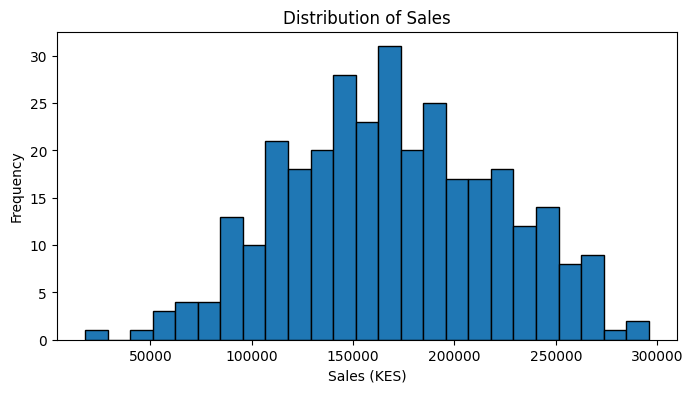

In [3]:
print("Missing values:")
display(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

display(df.describe(include="all"))

print("\nSales KES summary:")
print(df["Sales_KES"].describe())

# Plot distribution of Sales
plt.figure(figsize=(8, 4))
plt.hist(df["Sales_KES"], bins=25, edgecolor="black")
plt.title("Distribution of Sales")
plt.xlabel("Sales (KES)")
plt.ylabel("Frequency")
plt.show()

In [4]:
X = df.drop(columns="Sales_KES")
y = df["Sales_KES"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (320, 6)
y shape: (320,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 256
Test rows: 64


In [6]:
numeric_features = ["AdvertisingSpend_KES", "StoreVisits", "DiscountPercent"]
categorical_features = ["Region", "CustomerSegment", "ProductCategory"]

In [7]:
numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

In [8]:
preprocessor = ColumnTransformer(
    [
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

In [9]:
mean_baseline = DummyRegressor(strategy="mean")
median_baseline = DummyRegressor(strategy="median")

mean_baseline.fit(X_train, y_train)
median_baseline.fit(X_train, y_train)

mean_pred = mean_baseline.predict(X_test)
median_pred = median_baseline.predict(X_test)

In [10]:
def evaluate_regression(y_true, y_pred, name):
    return pd.DataFrame(
        {
            "Model": [name],
            "MAE": [mean_absolute_error(y_true, y_pred)],
            "RMSE": [np.sqrt(mean_squared_error(y_true, y_pred))],
            "R2": [r2_score(y_true, y_pred)],
        }
    )


mean_results = evaluate_regression(y_test, mean_pred, "Mean Baseline")
median_results = evaluate_regression(y_test, median_pred, "Median Baseline")
pd.concat([mean_results, median_results], ignore_index=True)

,Model,MAE,RMSE,R2
0,Mean Baseline,39197.156982,48716.433918,-0.008396
1,Median Baseline,39146.750000,48649.470528,-0.005626


In [11]:
linear_model = Pipeline(
    [("preprocess", preprocessor), ("model", LinearRegression())]
)

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_results = evaluate_regression(y_test, linear_pred, "Linear Regression")
linear_results

,Model,MAE,RMSE,R2
0,Linear Regression,13757.843478,17469.693466,0.870327


In [12]:
ridge_model = Pipeline(
    [("preprocess", preprocessor), ("model", Ridge(alpha=1.0))]
)

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

ridge_results = evaluate_regression(y_test, ridge_pred, "Ridge Regression")
ridge_results

,Model,MAE,RMSE,R2
0,Ridge Regression,13714.400361,17458.820721,0.870488


In [13]:
tree_model = Pipeline(
    [
        ("preprocess", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=4,
                min_samples_leaf=8,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

tree_results = evaluate_regression(y_test, tree_pred, "Decision Tree")
tree_results

,Model,MAE,RMSE,R2
0,Decision Tree,23775.92494,28767.642109,0.648368


In [14]:
comparison = pd.concat(
    [mean_results, median_results, linear_results, ridge_results, tree_results],
    ignore_index=True,
)
comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
3,Ridge Regression,13714.400361,17458.820721,0.870488
2,Linear Regression,13757.843478,17469.693466,0.870327
4,Decision Tree,23775.924940,28767.642109,0.648368
1,Median Baseline,39146.750000,48649.470528,-0.005626
0,Mean Baseline,39197.156982,48716.433918,-0.008396


In [15]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Decision Tree": tree_model,
}

rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=5, scoring=scoring)
    rows.append(
        {
            "Model": name,
            "CV_MAE": -scores["test_MAE"].mean(),
            "CV_RMSE": -scores["test_RMSE"].mean(),
            "CV_R2": scores["test_R2"].mean(),
        }
    )

cv_results = pd.DataFrame(rows)
cv_results

,Model,CV_MAE,CV_RMSE,CV_R2
0,Linear Regression,15976.774926,20126.771067,0.847517
1,Ridge Regression,15971.368173,20103.541323,0.847907
2,Decision Tree,24498.468304,30608.682961,0.650627


,Actual,Predicted,Residual
0,149359,136532.314107,12826.685893
1,198924,196021.086894,2902.913106
2,152671,143638.944984,9032.055016
3,133621,172495.435274,-38874.435274
4,171171,149069.696640,22101.303360


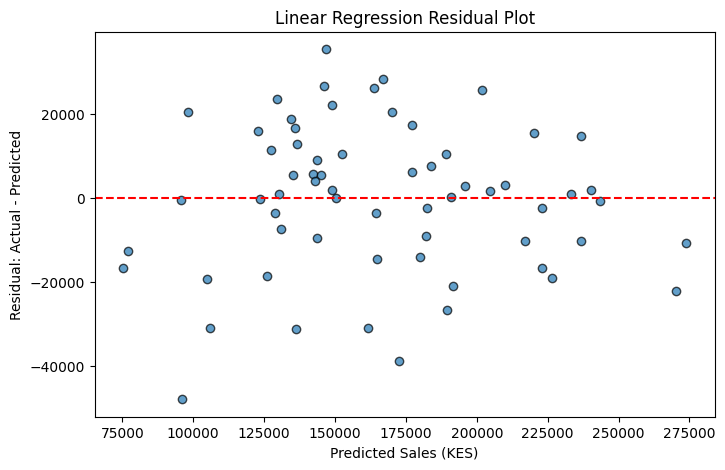

In [16]:
residuals = y_test - linear_pred
residual_df = pd.DataFrame(
    {"Actual": y_test.values, "Predicted": linear_pred, "Residual": residuals.values}
)
display(residual_df.head())

plt.figure(figsize=(8, 5))
plt.scatter(linear_pred, residuals, alpha=0.7, edgecolor="k")
plt.axhline(0, color="red", linestyle="--")
plt.title("Linear Regression Residual Plot")
plt.xlabel("Predicted Sales (KES)")
plt.ylabel("Residual: Actual - Predicted")
plt.show()

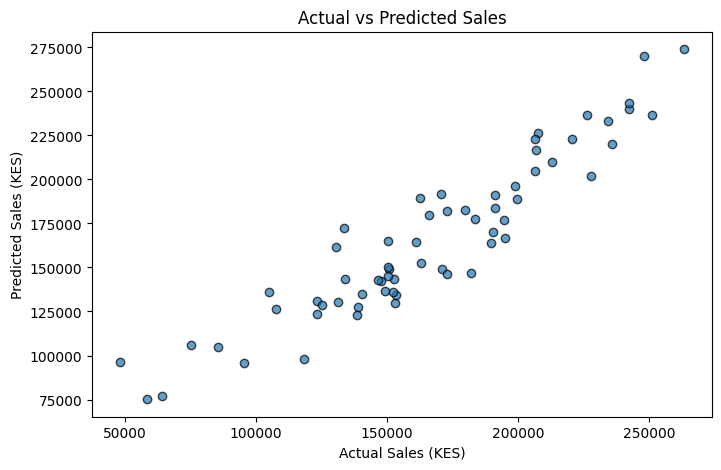

In [17]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, linear_pred, alpha=0.7, edgecolor="k")
plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales (KES)")
plt.ylabel("Predicted Sales (KES)")
plt.show()

In [18]:
error_analysis = X_test.copy()
error_analysis["ActualSales"] = y_test
error_analysis["PredictedSales"] = linear_pred
error_analysis["Residual"] = (
    error_analysis["ActualSales"] - error_analysis["PredictedSales"]
)
error_analysis["AbsoluteError"] = error_analysis["Residual"].abs()
error_analysis.sort_values("AbsoluteError", ascending=False).head(10)

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,ActualSales,PredictedSales,Residual,AbsoluteError
139,33386,161,22,Nairobi,Retail,Home,48229,96088.854657,-47859.854657,47859.854657
63,67888,265,4,Nakuru,SME,Accessories,133621,172495.435274,-38874.435274,38874.435274
46,33969,441,10,Nakuru,Retail,Accessories,182186,146807.115940,35378.884060,35378.884060
7,50328,108,13,Nairobi,Retail,Electronics,104994,136091.949761,-31097.949761,31097.949761
5,60808,257,8,Nairobi,Retail,Accessories,130757,161701.195990,-30944.195990,30944.195990
76,26462,114,13,Nairobi,Retail,Electronics,75103,106000.271668,-30897.271668,30897.271668
260,56576,151,0,Nairobi,Corporate,Home,195145,166919.218106,28225.781894,28225.781894
226,57562,410,21,Kisumu,Corporate,Office,162770,189424.021603,-26654.021603,26654.021603
73,13444,541,19,Nakuru,Retail,Electronics,172866,146216.703107,26649.296893,26649.296893
297,33529,285,3,Nairobi,Corporate,Office,189884,163816.773893,26067.226107,26067.226107


In [19]:
segment_errors = (
    error_analysis.groupby("CustomerSegment")
    .agg(
        Observations=("AbsoluteError", "size"),
        MAE=("AbsoluteError", "mean"),
    )
    .reset_index()
)
segment_errors

,CustomerSegment,Observations,MAE
0,Corporate,19,14300.002844
1,Retail,27,15560.578163
2,SME,18,10481.462121


In [20]:
tree_train_pred = tree_model.predict(X_train)

print(
    "Shallow Tree Training MAE:",
    round(mean_absolute_error(y_train, tree_train_pred), 2),
)
print(
    "Shallow Tree Test MAE:",
    round(mean_absolute_error(y_test, tree_pred), 2),
)

Shallow Tree Training MAE: 18029.7
Shallow Tree Test MAE: 23775.92


In [21]:
deep_tree = Pipeline(
    [
        ("preprocess", preprocessor),
        ("model", DecisionTreeRegressor(random_state=RANDOM_STATE)),
    ]
)

deep_tree.fit(X_train, y_train)
deep_train_pred = deep_tree.predict(X_train)
deep_test_pred = deep_tree.predict(X_test)

print(
    "Deep Tree Training MAE:",
    round(mean_absolute_error(y_train, deep_train_pred), 2),
)
print(
    "Deep Tree Test MAE:",
    round(mean_absolute_error(y_test, deep_test_pred), 2),
)

Deep Tree Training MAE: 0.0
Deep Tree Test MAE: 26797.5
